## Decision Trees and Random Forests

### 1. Dependencies

In [1]:
from prep import *
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score

X_train, X_test, y_train, y_test, meta = load_model_data()
print(f"{X_train.shape[1]} lagged features, {len(X_train)} training quarters")
print(f"target range in training: {y_train.min():.2f} to {y_train.max():.2f}; "
      f"test: {y_test.min():.2f} to {y_test.max():.2f}")

train 1992-03-31 to 2014-12-31  (92, 27)
test  2015-03-31 to 2025-12-31  (44, 27)
27 lagged features, 92 training quarters
target range in training: 0.48 to 3.36; test: 0.29 to 1.23


> **Note:** If the test range goes outside the training range, a tree **cannot** forecast those values.

### 2. Decision Tree

In [2]:
tree_pipe = make_pipeline(*preprocess(scale=False), DecisionTreeRegressor(random_state=0))
tree_grid = {"decisiontreeregressor__max_depth": [1, 2, 3, 4, 5, 6, 8, None],
             "decisiontreeregressor__min_samples_leaf": [1, 2, 4, 8, 12]}
tree_search = tune(tree_pipe, tree_grid, X_train, y_train)
tree_best = tree_search.best_estimator_

best params: {'decisiontreeregressor__max_depth': 4, 'decisiontreeregressor__min_samples_leaf': 8}
best CV root_mean_squared_error: 0.4648


<Axes: title={'center': 'Tuning: max_depth by min_samples_leaf'}, xlabel='max_depth', ylabel='root mean squared error'>

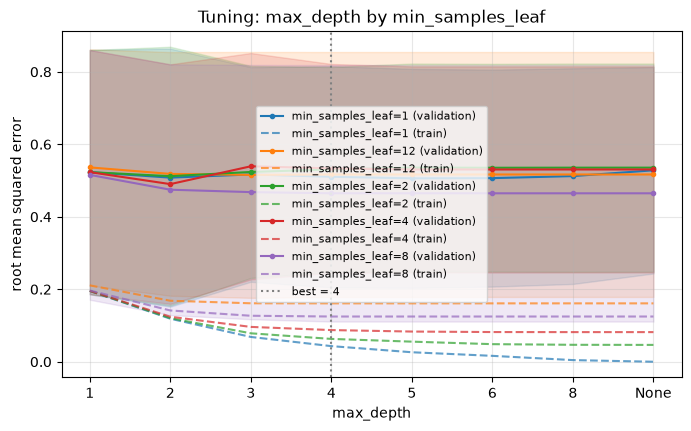

In [3]:
plot_tuning(tree_search, "decisiontreeregressor__max_depth", by="decisiontreeregressor__min_samples_leaf", logx=False)

<Axes: title={'center': 'CV root mean squared error'}, xlabel='max_depth', ylabel='min_samples_leaf'>

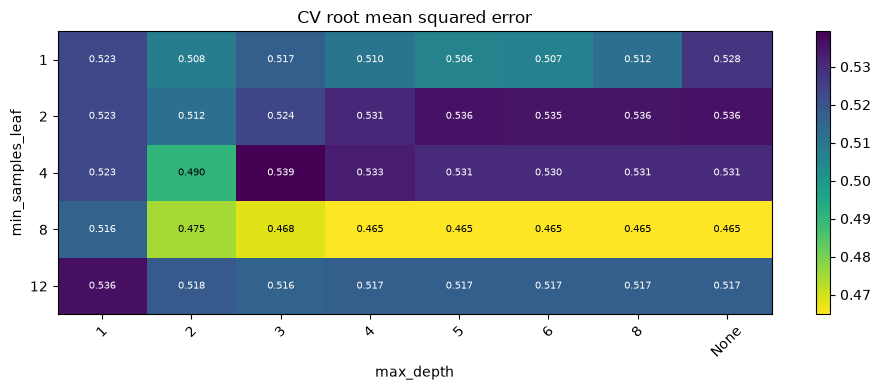

In [4]:
plot_tuning_heatmap(tree_search, "decisiontreeregressor__max_depth", "decisiontreeregressor__min_samples_leaf")

> **Note:** Deep trees with tiny leaves (top-right of the heatmap, `max_depth=None`, `min_samples_leaf=1`) drive training error toward 0 while validation error rises: the textbook picture of overfitting.

#### 1. Results

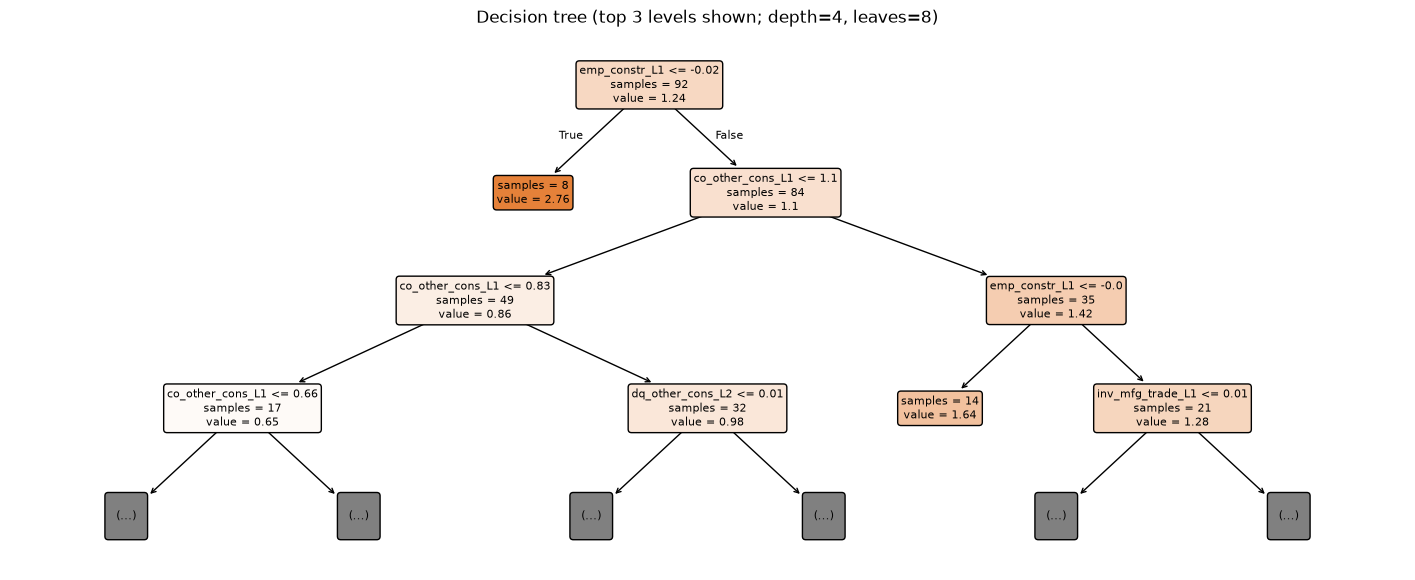

In [5]:
tree_fit = tree_best[-1]
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(tree_fit, feature_names=list(X_train.columns), max_depth=3, filled=True, rounded=True,
          precision=2, fontsize=8, ax=ax, impurity=False)
ax.set_title(f"Decision tree (top 3 levels shown; depth={tree_fit.get_depth()}, leaves={tree_fit.get_n_leaves()})")
plt.show()

In [6]:
print(export_text(tree_fit, feature_names=list(X_train.columns), max_depth=4, decimals=2))

|--- emp_constr_L1 <= -0.02
|   |--- value: [2.75]
|--- emp_constr_L1 >  -0.02
|   |--- co_other_cons_L1 <= 1.10
|   |   |--- co_other_cons_L1 <= 0.83
|   |   |   |--- co_other_cons_L1 <= 0.66
|   |   |   |   |--- value: [0.56]
|   |   |   |--- co_other_cons_L1 >  0.66
|   |   |   |   |--- value: [0.74]
|   |   |--- co_other_cons_L1 >  0.83
|   |   |   |--- dq_other_cons_L2 <= 0.01
|   |   |   |   |--- value: [0.93]
|   |   |   |--- dq_other_cons_L2 >  0.01
|   |   |   |   |--- value: [1.08]
|   |--- co_other_cons_L1 >  1.10
|   |   |--- emp_constr_L1 <= -0.00
|   |   |   |--- value: [1.64]
|   |   |--- emp_constr_L1 >  -0.00
|   |   |   |--- inv_mfg_trade_L1 <= 0.01
|   |   |   |   |--- value: [1.38]
|   |   |   |--- inv_mfg_trade_L1 >  0.01
|   |   |   |   |--- value: [1.12]



> **Note:** Each path from the top to a leaf is a rule, e.g. *if last quarter's delinquency > x and unemployment > y, forecast z*.

<Axes: title={'center': 'Decision tree: impurity importance'}>

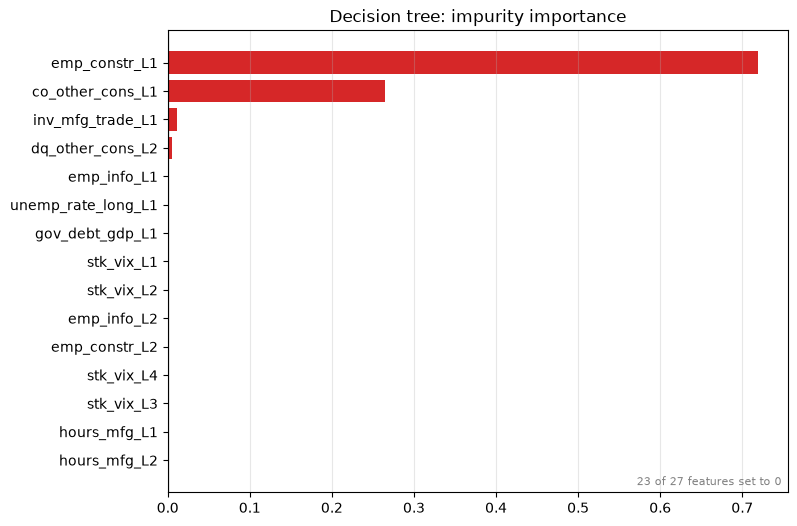

In [7]:
plot_feature_weights(tree_best, X_train, top=15, title="Decision tree: impurity importance")

In [8]:
score(tree_best, X_train, X_test, y_train, y_test)

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.184,0.121,0.904,0.717,92.0
model - test,0.368,0.178,-1.094,0.500,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.164,0.135,0.397,0.528,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


<Axes: title={'center': 'Decision tree: forecasts are step-shaped (one value per leaf)'}, ylabel='co_other_cons'>

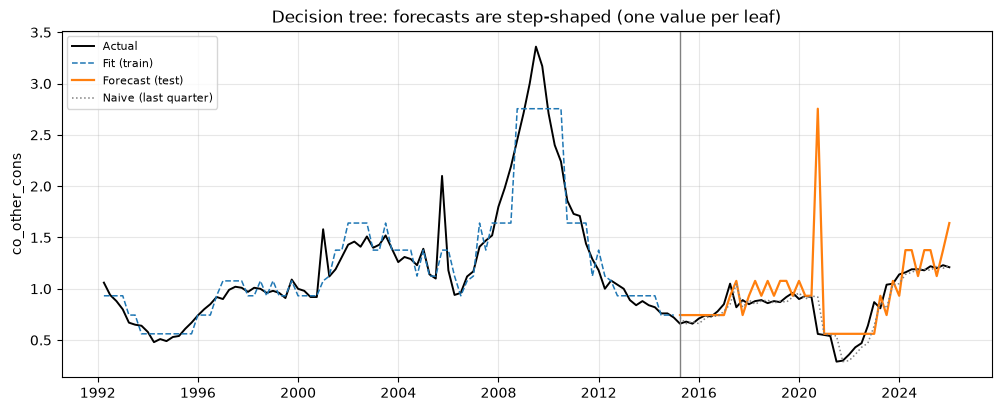

In [9]:
plot_forecast(tree_best, X_train, X_test, y_train, y_test, title="Decision tree: forecasts are step-shaped (one value per leaf)")

#### 2. Cost-Complexity Pruning
Grow a full tree, then remove the weakest branches. `ccp_alpha` is the price per leaf: larger values prune more.

best params: {'decisiontreeregressor__ccp_alpha': np.float64(0.0)}
best CV root_mean_squared_error: 0.4648


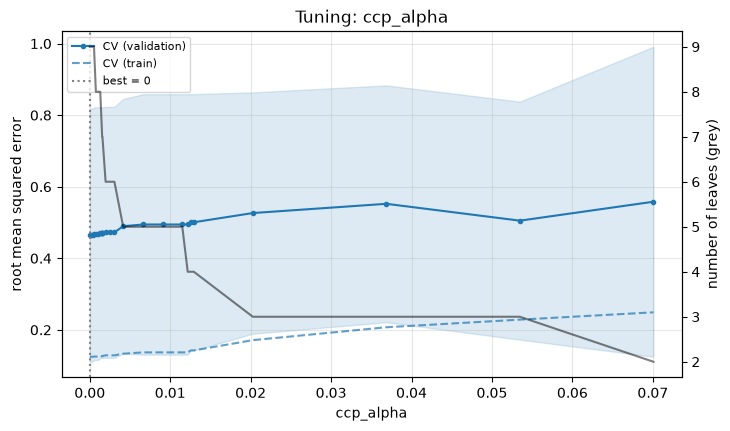

In [10]:
leaf = tree_search.best_params_["decisiontreeregressor__min_samples_leaf"]
full = make_pipeline(*preprocess(scale=False), DecisionTreeRegressor(random_state=0, min_samples_leaf=leaf))
Xi = full[:-1].fit_transform(X_train)
path = DecisionTreeRegressor(random_state=0, min_samples_leaf=leaf).cost_complexity_pruning_path(Xi, y_train)
alphas = np.unique(np.quantile(path.ccp_alphas[:-1], np.linspace(0, 1, 25)))   # 25 representative values

prune_search = tune(full, {"decisiontreeregressor__ccp_alpha": alphas}, X_train, y_train)
pruned_best = prune_search.best_estimator_

rows = []
for a in alphas:
    m = make_pipeline(*preprocess(scale=False), DecisionTreeRegressor(random_state=0, min_samples_leaf=leaf, ccp_alpha=a)).fit(X_train, y_train)
    rows.append({"ccp_alpha": a, "leaves": m[-1].get_n_leaves()})
leaves = pd.DataFrame(rows)

ax = plot_tuning(prune_search, "decisiontreeregressor__ccp_alpha", logx=False)
ax2 = ax.twinx(); ax2.plot(leaves["ccp_alpha"], leaves["leaves"], color="black", alpha=0.5)
ax2.set_ylabel("number of leaves (grey)"); plt.show()

In [11]:
display(score(pruned_best, X_train, X_test, y_train, y_test))
print(f"pruned tree: {pruned_best[-1].get_n_leaves()} leaves, depth {pruned_best[-1].get_depth()}")

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.182,0.117,0.906,0.761,92.0
model - test,0.368,0.177,-1.090,0.477,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.163,0.131,0.406,0.500,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


pruned tree: 9 leaves, depth 5


In [12]:
# keep whichever tree did better in cross-validation
tree_final, tree_src = (pruned_best, prune_search) if prune_search.best_score_ > tree_search.best_score_ else (tree_best, tree_search)
record("Decision tree", tree_final, X_train, X_test, y_train, y_test, search=tree_src,
       notes=f"{tree_final[-1].get_n_leaves()} leaves, depth {tree_final[-1].get_depth()}; {tree_src.best_params_}")

recorded 'Decision tree' -> /workspaces/DX799-O1/model_data/results


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.184,0.121,0.904,0.717,92.0
model - test,0.368,0.178,-1.094,0.500,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.164,0.135,0.397,0.528,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


### 2. Random Forest

In [13]:
rf_pipe = make_pipeline(*preprocess(scale=False), RandomForestRegressor(random_state=0, n_jobs=1))
rf_grid = {"randomforestregressor__n_estimators": [200, 500],
           "randomforestregressor__max_depth": [2, 3, 5, 8, None],
           "randomforestregressor__min_samples_leaf": [1, 3, 5, 8],
           "randomforestregressor__max_features": [0.2, 0.33, 0.5, 1.0]}
# random search: 40 of the 160 combinations, to keep run time reasonable
rf_search = tune(rf_pipe, rf_grid, X_train, y_train, search="random", n_iter=40)
rf_best = rf_search.best_estimator_

best params: {'randomforestregressor__n_estimators': 200, 'randomforestregressor__min_samples_leaf': 1, 'randomforestregressor__max_features': 1.0, 'randomforestregressor__max_depth': 8}
best CV root_mean_squared_error: 0.4624


<Axes: title={'center': 'Tuning: max_depth by max_features'}, xlabel='max_depth', ylabel='root mean squared error'>

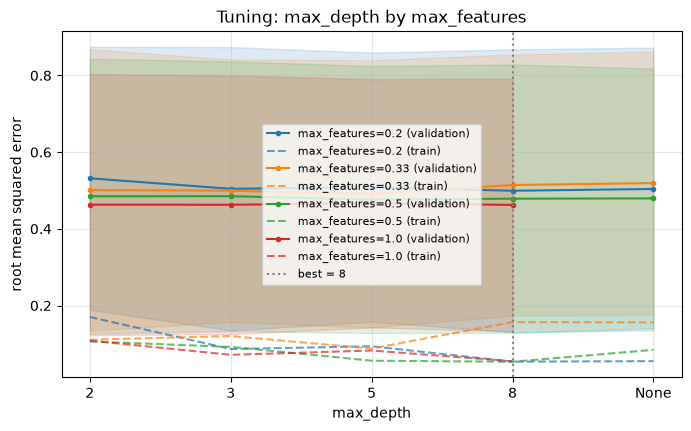

In [15]:
plot_tuning(rf_search, "randomforestregressor__max_depth", by="randomforestregressor__max_features", logx=False)

<Axes: title={'center': 'CV root mean squared error'}, xlabel='max_features', ylabel='min_samples_leaf'>

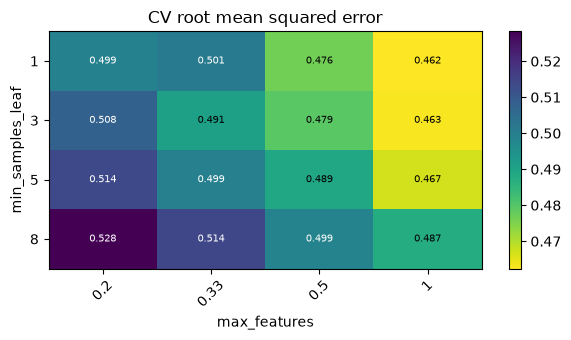

In [16]:
plot_tuning_heatmap(rf_search, "randomforestregressor__max_features", "randomforestregressor__min_samples_leaf")

> **Note:** `max_features` = share of features each split may consider. Smaller values make the trees more different from each other, which makes averaging more effective (often the most important random-forest setting).

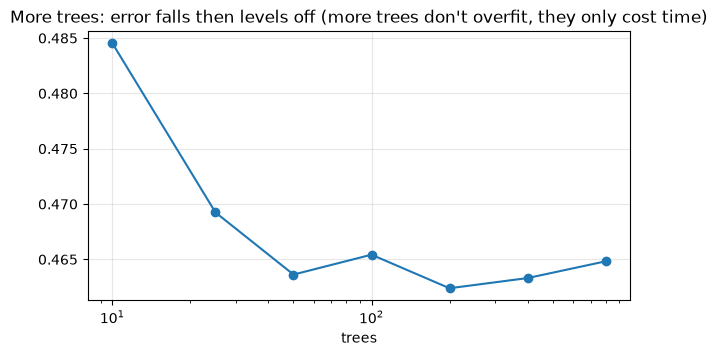

In [17]:
# does adding more trees help? (other settings at their best)
best_rf = {k: v for k, v in rf_search.best_params_.items() if "n_estimators" not in k}
rows = []
for n in [10, 25, 50, 100, 200, 400, 800]:
    m = make_pipeline(*preprocess(scale=False), RandomForestRegressor(random_state=0, n_jobs=-1)).set_params(
        **best_rf, randomforestregressor__n_estimators=n)
    cv = -cross_val_score(m, X_train, y_train, cv=TimeSeriesSplit(5), scoring="neg_root_mean_squared_error").mean()
    rows.append({"trees": n, "CV RMSE": cv})
ntrees = pd.DataFrame(rows)
ax = ntrees.plot(x="trees", y="CV RMSE", marker="o", logx=True, figsize=(7, 3.5), legend=False)
ax.set_title("More trees: error falls then levels off (more trees don't overfit, they only cost time)")
ax.grid(alpha=0.3); plt.show()

#### 1. Weights and Feature Importance

<Axes: title={'center': 'Random forest: impurity importance'}>

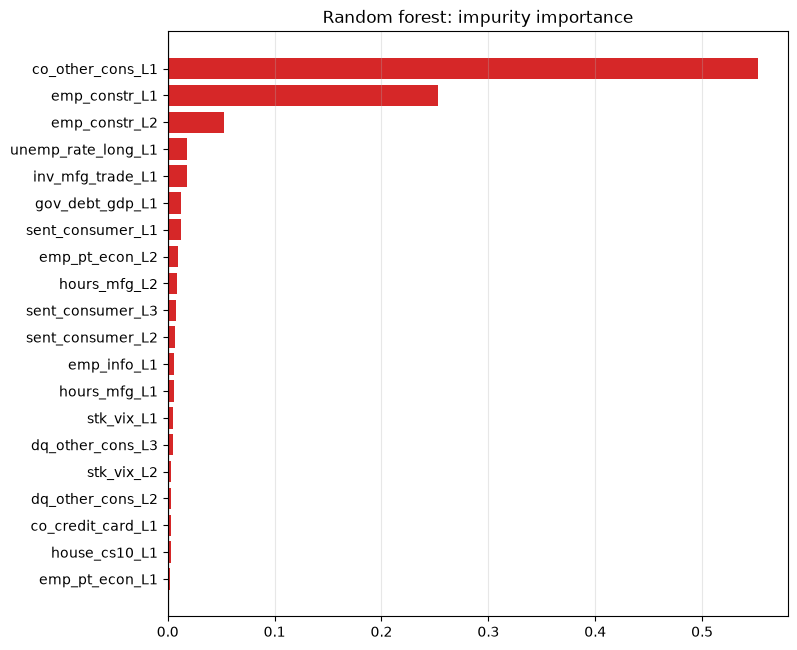

In [18]:
plot_feature_weights(rf_best, X_train, top=20, title="Random forest: impurity importance")

<Axes: title={'center': 'Permutation importance (big train, small test = likely overfit)'}, xlabel='drop in root_mean_squared_error when shuffled'>

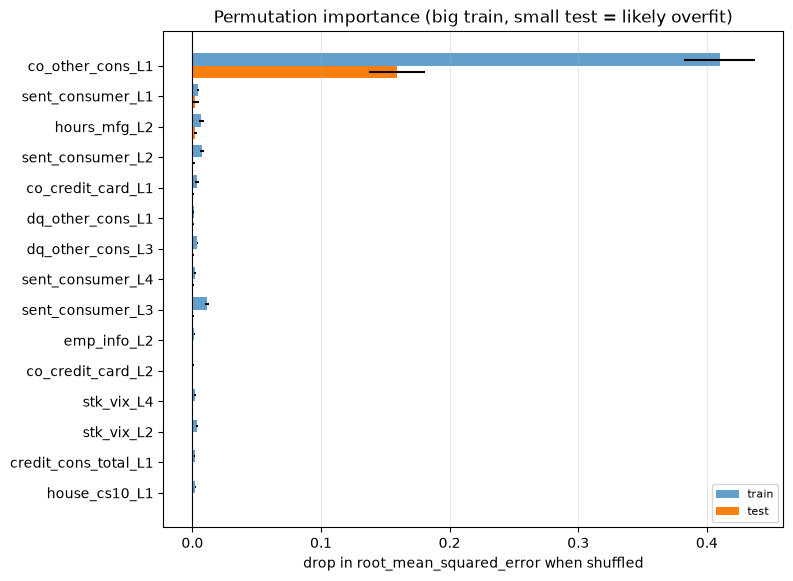

In [19]:
perm_rf = permutation_table(rf_best, X_train, y_train, X_test, y_test, n_repeats=15)
plot_permutation(perm_rf, top=15)

> **Note:** Impurity importance (first chart) is computed on the training data and favours features with many distinct values; permutation importance (second) is more reliable and shows train vs test. Where they disagree, trust permutation.

,full-training weight,mean across folds,sd across folds,share of folds used,sign flips
feature,,,,,
co_other_cons_L1,0.552,0.384,0.202,1.0,False
emp_constr_L1,0.253,0.089,0.120,1.0,False
emp_constr_L2,0.053,0.043,0.021,1.0,False
unemp_rate_long_L1,0.018,0.018,0.022,1.0,False
inv_mfg_trade_L1,0.018,0.022,0.023,1.0,False
gov_debt_gdp_L1,0.013,0.008,0.006,1.0,False
sent_consumer_L1,0.012,0.008,0.010,1.0,False
emp_pt_econ_L2,0.010,0.009,0.005,1.0,False
hours_mfg_L2,0.008,0.028,0.031,1.0,False


<Axes: title={'center': 'Weight stability across time folds (dots = folds, bar = full training)'}>

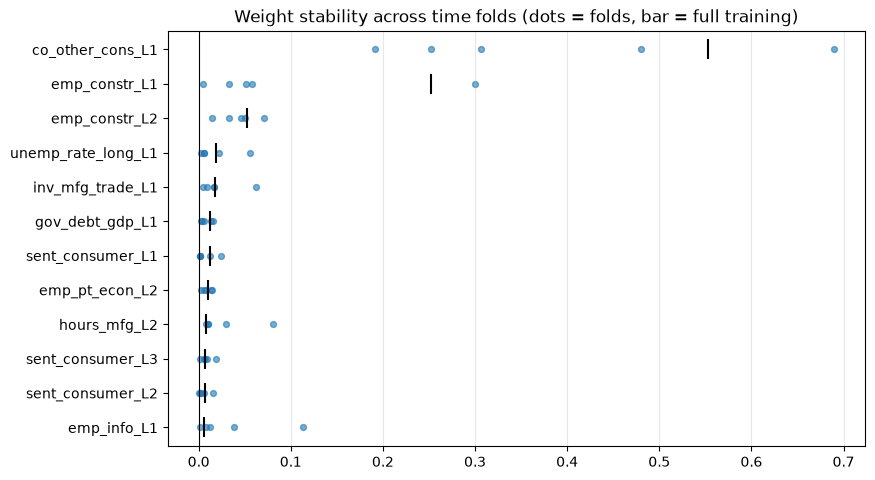

In [20]:
W_rf, stab_rf = weight_stability(rf_best, X_train, y_train)
display(stab_rf.head(12).round(3))
plot_weight_stability(W_rf, top=12)

#### 2. Extrapolation: Trees vs a Linear Model

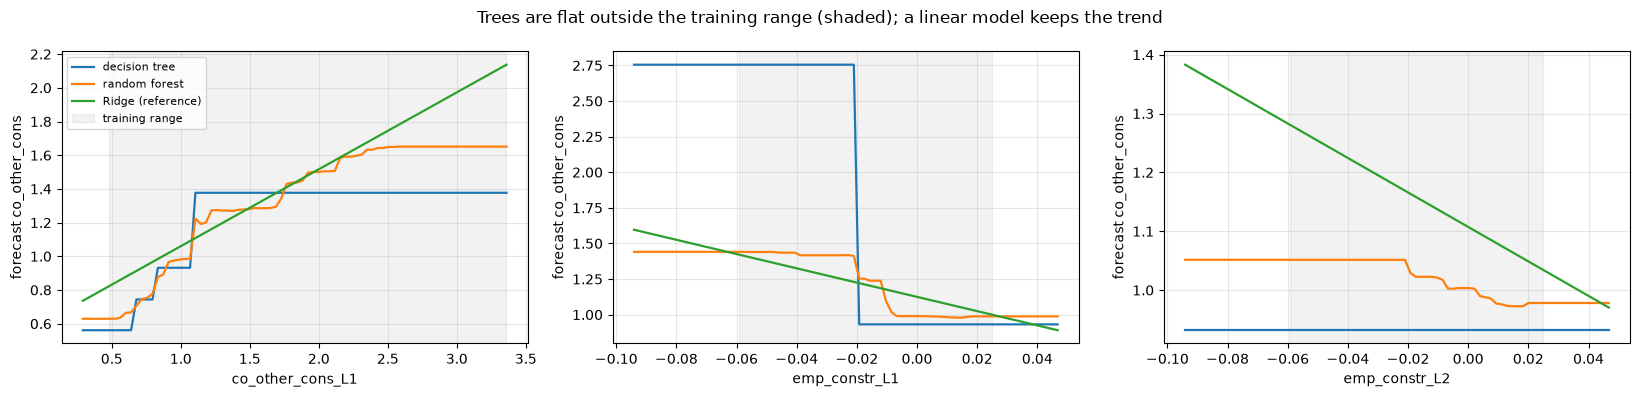

In [21]:
ridge_ref = make_pipeline(*preprocess(scale=True), Ridge(alpha=10)).fit(X_train, y_train)
models_rc = {"decision tree": tree_final, "random forest": rf_best, "Ridge (reference)": ridge_ref}
top_feats = list(perm_rf["train importance"].sort_values(ascending=False).index[:3])

fig, axes = plt.subplots(1, len(top_feats), figsize=(5.5 * len(top_feats), 4), squeeze=False)
base = X_train.median()
for ax, f in zip(axes[0], top_feats):
    lo = min(X_train[f].min(), X_test[f].min()); hi = max(X_train[f].max(), X_test[f].max())
    grid = np.linspace(lo, hi, 80)
    Xg = pd.DataFrame([base] * len(grid)).reset_index(drop=True); Xg[f] = grid
    for name, m in models_rc.items():
        ax.plot(grid, m.predict(Xg), label=name, lw=1.6)
    ax.axvspan(X_train[f].min(), X_train[f].max(), color="grey", alpha=0.1, label="training range")
    ax.set_xlabel(f); ax.set_ylabel(f"forecast {meta['target']}"); ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Trees are flat outside the training range (shaded); a linear model keeps the trend")
plt.tight_layout(); plt.show()

In [22]:
score(rf_best, X_train, X_test, y_train, y_test)

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.087,0.052,0.979,0.946,92.0
model - test,0.216,0.125,0.278,0.545,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.115,0.084,0.705,0.583,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


<Axes: title={'center': 'Random forest: actual vs forecast'}, ylabel='co_other_cons'>

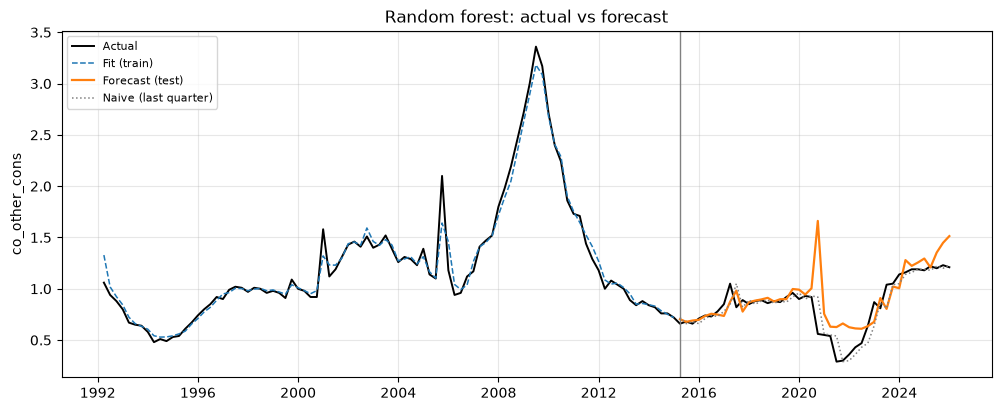

In [23]:
plot_forecast(rf_best, X_train, X_test, y_train, y_test, title="Random forest: actual vs forecast")

In [24]:
record("Random forest", rf_best, X_train, X_test, y_train, y_test, search=rf_search, notes=str(rf_search.best_params_))

recorded 'Random forest' -> /workspaces/DX799-O1/model_data/results


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.087,0.052,0.979,0.946,92.0
model - test,0.216,0.125,0.278,0.545,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.115,0.084,0.705,0.583,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


### 3. RF Classifier on Y/N Target
Same question as notebooks 4–5; tuned on accuracy with 12-quarter validation blocks.

In [25]:
y_train_bin, y_test_bin, thr = make_binary_target(y_train, y_test)
CV_CLS = TimeSeriesSplit(n_splits=4, test_size=12)
rfc_search = tune(make_pipeline(*preprocess(scale=False), RandomForestClassifier(random_state=0, n_jobs=1)),
                  {"randomforestclassifier__n_estimators": [300],
                   "randomforestclassifier__max_depth": [2, 3, 5, None],
                   "randomforestclassifier__min_samples_leaf": [1, 3, 5, 8],
                   "randomforestclassifier__max_features": [0.2, 0.33, 0.5]},
                  X_train, y_train_bin, cv=CV_CLS, scoring="accuracy", search="random", n_iter=25)
rfc_best = rfc_search.best_estimator_
score_classifier(rfc_best, X_train, X_test, y_train_bin, y_test_bin)

threshold = 1.050 (training 50% quantile); share above: train 50%, test 20%
best params: {'randomforestclassifier__n_estimators': 300, 'randomforestclassifier__min_samples_leaf': 8, 'randomforestclassifier__max_features': 0.5, 'randomforestclassifier__max_depth': 2}
best CV accuracy: 0.7500


,Accuracy,Precision,Recall,F1,ROC_AUC,n
train (in-sample),0.924,0.933,0.913,0.923,0.991,92.0
test,0.977,1.000,0.889,0.941,1.000,44.0
always-majority - test,0.795,NaN,NaN,NaN,NaN,44.0


In [26]:
record("Random forest (classifier)", rfc_best, X_train, X_test, y_train_bin, y_test_bin, search=rfc_search,
       notes=f"high = above training median {thr:.3f}; {rfc_search.best_params_}")

recorded 'Random forest (classifier)' -> /workspaces/DX799-O1/model_data/results


,Accuracy,Precision,Recall,F1,ROC_AUC,n
train (in-sample),0.924,0.933,0.913,0.923,0.991,92.0
test,0.977,1.000,0.889,0.941,1.000,44.0
always-majority - test,0.795,NaN,NaN,NaN,NaN,44.0


### 4. Walk-Forward Check for Tree Models
Refit each year on all data up to that point and forecast the next quarters: closer to how a forecaster would actually use the model.

walk-forward RMSE: {'naive': 0.104, 'Decision tree': 0.152, 'Random forest': 0.2}


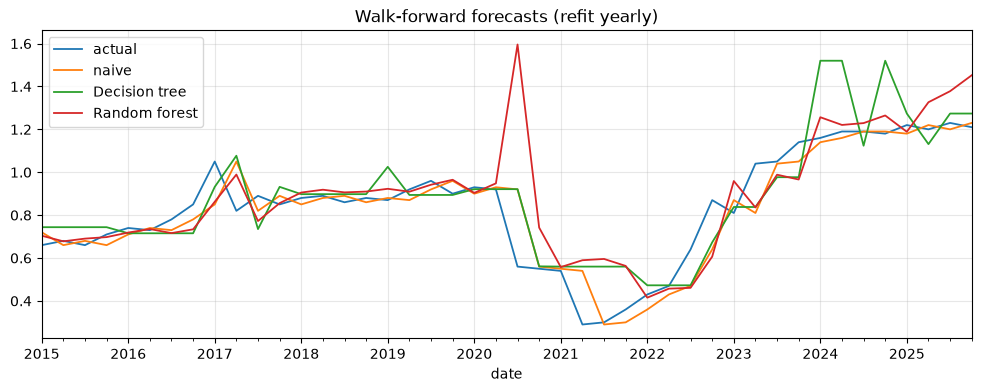

In [27]:
X_all, y_all = load_full()
X_all, y_all = X_all.loc[X_train.index.min():], y_all.loc[X_train.index.min():]
wf = pd.DataFrame({"actual": y_all.loc["2015":], "naive": X_all.loc["2015":, f"{meta['target']}_L1"]})
for name, m in {"Decision tree": tree_final, "Random forest": rf_best}.items():
    wf[name] = walk_forward(m, X_all, y_all, "2015", refit_every=4)
rmse = {c: float(np.sqrt(((wf[c] - wf["actual"]) ** 2).mean())) for c in wf.columns if c != "actual"}
print("walk-forward RMSE:", {k: round(v, 3) for k, v in rmse.items()})
ax = wf.plot(figsize=(12, 4), lw=1.3); ax.set_title("Walk-forward forecasts (refit yearly)"); ax.grid(alpha=0.3); plt.show()

In [28]:
export_recorded()      # all_models_test_predictions.csv + all_models_metrics.csv
export_predictions(rf_best, X_train, X_test, y_train, y_test, name="Random forest")
export_predictions(tree_final, X_train, X_test, y_train, y_test, name="Decision tree")
wf.to_csv(f"{EXPORT_DIR}/nb6_walk_forward.csv")

saved -> /workspaces/DX799-O1/model_data/exports/all_models_test_predictions.csv
saved -> /workspaces/DX799-O1/model_data/exports/all_models_metrics.csv
saved 136 rows -> /workspaces/DX799-O1/model_data/exports/Random_forest_predictions.csv
saved 136 rows -> /workspaces/DX799-O1/model_data/exports/Decision_tree_predictions.csv


### 4. Notes

**Goal:** forecast `co_other_cons` with tree-based models, see how their regularization works, and compare every model from notebooks 1–6.

**Decision tree:** repeatedly splits the quarters on one feature at a time ("is `dq_other_cons_L1` > 2.4?") and predicts the average of the training quarters in each final group (**leaf**). It captures non-linearities and interactions automatically, but a deep tree memorizes the training data.

**Tree regularization:**
- `max_depth`: how many splits deep (shallow = simple)
- `min_samples_leaf`: smallest group allowed in a leaf (larger = smoother, less overfitting)
- `ccp_alpha`: cost-complexity **pruning**, which removes branches that don't improve fit enough

**Random forest:** many trees, each grown on a bootstrap resample of quarters and only allowed to consider a random subset of features at each split (`max_features`), then averaged. Averaging many different trees cancels much of the overfitting of any single tree.

**Things specific to trees:**
- **No scaling needed:** splits only depend on the order of values.
- **No extrapolation:** a tree can only predict values it has seen in training (leaf averages). If test-period values fall outside the training range, forecasts flatten, which matters for 2020–21.
- **Out-of-bag (OOB) score is not used:** it scores each tree on randomly left-out quarters, which ignores time order; time-ordered CV is used instead.
- **Lags:** trees choose whichever lag splits best at each step, and can combine lags of different variables in one branch (an interaction).

- **Tree regularization:** best depth / leaf size, the depth × leaf heatmap, and cost-complexity pruning (leaves vs CV error).
- **Random forest:** effect of `max_features` and depth; more trees level off rather than overfit; impurity vs permutation importance.
- **Extrapolation:** trees cannot forecast beyond the training range (response-curve chart), which matters for 2020–21 and any new highs.
- **Final comparison:** which models beat the naive forecast (with and without 2020–21), the overfitting gap for each, yes/no accuracy across regressors and classifiers, and the walk-forward check.
- **Conclusion:** if few models beat naive, the strongest finding is that charge-offs are highly persistent and macro variables add limited one-quarter-ahead information; say which variables helped most across models (delinquency, credit-card stress, spreads, labor market).